# Validation questions — ownership-breadth factor

A running set of questions about the factor's efficacy and the data behind it. Each
answer states the result first and ends with a chart or table that shows it.

**The factor:** the out-of-sample score of the 16-feature LightGBM model (13 breadth
features + size/value), from the purged & embargoed 5-fold CV used in the README
(12-month label) — the README's full model. Its size/value inputs come from **point-in-time**
market caps (as-traded price × SEC share count, share-count checked) and **point-in-time** SEC
issuer identities, and its breadth features come from 13F snapshots cut at the real filing
deadline. Its mean rank IC is **0.0706** (Newey-West t 3.6; naive t 5.6). Earlier versions of the
pipeline reported 0.072, 0.0644 and 0.0587. The first used split- and dividend-adjusted prices for
its caps, which leak the future (Q7). The second found each issuer's SEC filings through today's
tickers, which left later failures without size/value data (Q10). The third cut each quarter's 13F
snapshot at quarter-end + 46 days, at midnight, which dropped 22–31% of managers in 13 of 50
quarters whenever the deadline moved past a weekend or holiday, and corrupted the change features
(see the README's correction note). With that fixed, breadth's incremental IC over the size/value
baseline is **+0.022 (Newey-West t 3.6)**, up from +0.008 (t 1.1), and +0.020 (t 3.1) on names
with a trustworthy market cap.

**Findings at a glance**

| # | Question | Short answer |
|---|---|---|
| 1 | Are decile returns monotonic? | **Only the medians, roughly.** D1 beats the universe by 3.1% over 12 months, in 67% of quarters, but D10 has an even higher *mean* (+7.4%), carried by a few extreme small-cap winners. Medians fall almost steadily from D1 (2.6% above the universe) to D10 (8.4% below). |
| 2 | Which features survived? | 15 of 16 at 12 months, 10 at 6. Size/value have the largest SHAP values; HHI, exit rate and aggregate institutional shares lead the breadth features. At 12 months pruning drops only top-5 share; at 6 months it drops six, ΔBreadth among them. |
| 3 | Momentum proxy? | **No.** ~0 correlation with 12-1 momentum, and about 90% of IC survives removing it. Size overlaps more, but two-thirds of the breadth-only score's IC survives removing size. |
| 4 | Regime-dependent? | IC is higher when the 10-year yield is rising (0.095 vs 0.042), but only weakly (p ≈ 0.05 before adjusting for overlap). The level of rates doesn't matter. |
| 5 | Stable deciles? | Extremes are sticky (D1 keeps 63% of names quarter-on-quarter), the middle churns. About 38% of D1 is replaced each quarter. |
| 6 | Cap- vs equal-weighted L/S? | **Neither works.** EW D1−D10 loses 6%/yr; on names with trustworthy caps EW loses 8%/yr and VW 2%/yr. The long leg is the robust part: D1 beats its universe in every version, narrowly when cap-weighted. |
| 7 | Are the size/value inputs point-in-time? | **Now yes; originally no — a real look-ahead, since fixed.** Adjusted prices had understated 10% of caps by ≥1.5× (AMZN 20×, NVDA 40× in 2019). Replayed on today's pipeline, the leak is worth 0.006 IC to the full model and 0.012 to the size/value baseline. |
| 8 | Are SEC share counts sane? | 3.1% of stock-quarters (573 tickers) fail a 13F-vs-XBRL share-count check: ADR share ratios and filing scale errors. Phase 4 now treats their size/value features as missing. |
| 9 | Better on large or small caps? | **The factor works on small caps; breadth adds at every size.** Factor IC is 0.001–0.027 in the three largest cap quintiles and 0.074–0.129 in the two smallest, mostly from size/value. Breadth's increment is positive in all five (+0.014 to +0.040) and +0.020 (t 3.1) on names with a trustworthy cap, but in the large quintiles it mainly cancels a size/value score that ranks them wrongly. |
| 10 | How much of the IC came from names with no size/value data? | **Little, now.** 0.025 of the old 0.0644 came from ranking those names below the rest, mostly through a look-ahead in the SEC issuer mapping, since fixed. Of today's 0.0706 only 0.0075 is between-group, and missing-value splits are worth ≈0.001–0.003. |

**Conventions used throughout**
- Deciles are re-formed **every quarter** at the formation date (the first business day after the 13F filing deadline: quarter-end + 45 days, rolled past weekends and federal holidays), so constituents change each quarter. **D1 = highest score.**
- Universe: US-listed common stock, ADRs and REITs with ≥ 5 13F holders; 46 quarters (2014-Q1 to 2025-Q2).
- Returns are total (dividend-adjusted), equal-weighted unless stated, before costs. Names that drop out of the free price feed are missing, which biases returns upward, most of all for micro-caps.
- Not a live track record: under K-fold some quarters are scored by a model trained on *later* (purged, embargoed) data.
- t-statistics below are naive (quarters treated as independent) unless labelled Newey-West. 12-month returns measured every quarter overlap, so they overstate the evidence — by about 1.6× for the headline IC, whose Newey-West t is 3.6 rather than 5.6. Read t ≈ 2 as weak.

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import load_config
from src.backtest import validation as V
from src.backtest.cv import PurgedKFold
from src.backtest.metrics import ic_summary, newey_west_t, rank_ic
from src.backtest.model import run_cv_predictions

# --- chart style: light surface, recessive horizontal grid, 2px lines ---
SURF, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
# Deciles are ordered -> diverging ramp: blue (top) -> gray -> red (bottom).
DECILE_COLORS = {1: "#104281", 2: "#256abf", 3: "#5598e7", 4: "#86b6ef", 5: "#a8a7a0",
                 6: "#7c7b76", 7: "#ed9796", 8: "#e66563", 9: "#c93a39", 10: "#922423"}
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "lines.linewidth": 2, "figure.dpi": 110, "legend.frameon": False,
})
PCT = mtick.PercentFormatter(1.0, decimals=0)

def money(x):
    if not np.isfinite(x):
        return ""
    for div, unit in [(1e12, "T"), (1e9, "bn"), (1e6, "m"), (1e3, "k")]:
        if abs(x) >= div:
            return f"${x / div:,.1f}{unit}"
    return f"${x:,.0f}"

cfg = load_config()
vp = V.build_validation_panel(cfg)        # cached OOS scores, returns, momentum, caps
FACTOR = "score_full"                     # breadth + point-in-time size/value (README full model)
vp["decile"] = V.assign_deciles(vp, FACTOR)
TABLES = ROOT / "results" / "tables"

ic_factor = rank_ic(vp, FACTOR, "fwd_ret_12m")
s = ic_summary(ic_factor, nw_lags=4)        # 12m labels, quarterly: Newey-West, 4 lags
print(f"{len(vp):,} stock-quarters | {vp.period.nunique()} quarters "
      f"({vp.period.min():%Y-%m} to {vp.period.max():%Y-%m}) | "
      f"factor mean rank IC {s['mean_ic']:.4f} (Newey-West t {s['t_stat_nw']:.1f}; naive t {s['t_stat']:.1f})")

133,969 stock-quarters | 46 quarters (2014-03 to 2025-06) | factor mean rank IC 0.0706 (Newey-West t 3.6; naive t 5.6)


## 1. Are deciles ranked by return (D1 > D2 > … > D10)?

**Answer: no — only the medians are, roughly.** D1 earns 3.1% more than the universe over 12 months
on average and beats it in 67% of quarters, but its *mean* is not the highest: D10 averages
7.4% above the universe. Those means are carried by a few extreme winners (penny stocks,
meme rallies) among the small, thinly held names the factor ranks lowest. *Medians* tell the
intended story: D1's median is 2.6% above the universe's, D2's 2.2%, and from there they fall
almost steadily to D10, 8.4% below it. Held quarter to quarter, D1 compounds at about
15% a year, D9 at 14% and D10 at 16%, against 9–12% for D2–D8. The factor is better at
spotting typical losers than at picking winners, and its bottom decile is a lottery, which is why a
short D10 position fails (Q6).

*Assumptions:* deciles re-formed every quarter (constituents change); equal-weighted;
excess = decile minus the universe that quarter. The cumulative chart holds each quarterly
portfolio for 3 months until the next rebalance (no overlap), compounded, gross of costs.

In [2]:
r12 = V.decile_returns(vp, "fwd_ret_12m")                     # quarter x decile, mean
univ_mean = vp.groupby("period")["fwd_ret_12m"].mean()
med12 = vp.groupby(["period", "decile"])["fwd_ret_12m"].median().unstack()
univ_med = vp.groupby("period")["fwd_ret_12m"].median()
r3 = V.decile_returns(vp, "fwd_ret_3m")                       # next-quarter holding

q1 = pd.DataFrame({
    "Mean 12m return": r12.mean(),
    "Excess vs universe (mean)": r12.sub(univ_mean, axis=0).mean(),
    "Excess vs universe (median)": med12.sub(univ_med, axis=0).mean(),
    "% quarters beating universe": (r12.sub(univ_mean, axis=0) > 0).mean(),
    "CAGR, quarterly 3m-hold": (1 + r3).prod() ** (4 / len(r3)) - 1,
})
q1.index = [f"D{d}" for d in q1.index]
q1.index.name = "Decile"
q1.style.format("{:.1%}")

,Mean 12m return,Excess vs universe (mean),Excess vs universe (median),% quarters beating universe,"CAGR, quarterly 3m-hold"
Decile,,,,,
D1,18.0%,3.1%,2.6%,67.4%,14.8%
D2,13.9%,-1.0%,2.2%,47.8%,11.9%
D3,12.9%,-2.0%,1.5%,47.8%,11.4%
D4,12.8%,-2.1%,1.2%,39.1%,8.7%
D5,12.5%,-2.4%,0.4%,37.0%,10.9%
D6,13.4%,-1.5%,0.3%,39.1%,10.4%
D7,13.0%,-2.0%,-0.6%,28.3%,9.9%
D8,14.8%,-0.1%,-0.4%,50.0%,12.3%
D9,15.6%,0.7%,-2.6%,54.3%,14.3%


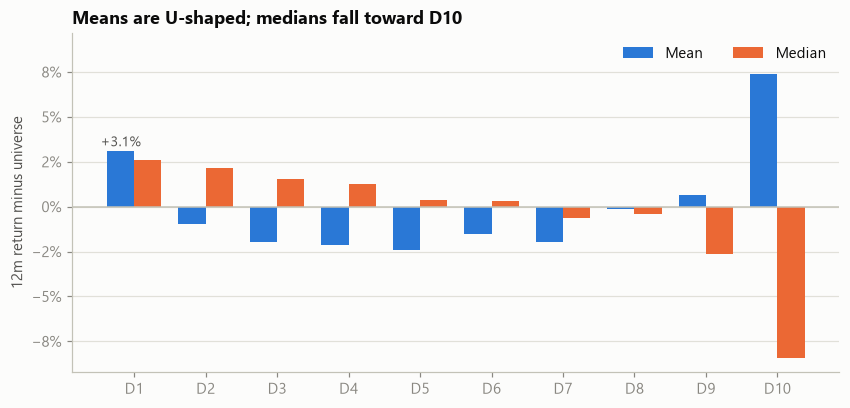

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(1, 11)
w = 0.38
ax.bar(x - w / 2, q1["Excess vs universe (mean)"], w, color=BLUE, label="Mean")
ax.bar(x + w / 2, q1["Excess vs universe (median)"], w, color=ORANGE, label="Median")
ax.axhline(0, color=AXIS, lw=1)
ax.set_xticks(x, [f"D{d}" for d in x])
ax.yaxis.set_major_formatter(PCT)
lo, hi = ax.get_ylim()
ax.set_ylim(lo, hi + 0.015)
ax.annotate(f"+{q1.iloc[0, 1]:.1%}", (1 - w / 2, q1.iloc[0, 1]), xytext=(0, 3),
            textcoords="offset points", ha="center", color=INK2, fontsize=9)
ax.set_ylabel("12m return minus universe")
ax.set_title("Means are U-shaped; medians fall toward D10")
ax.legend(loc="upper right", ncols=2)
plt.show()

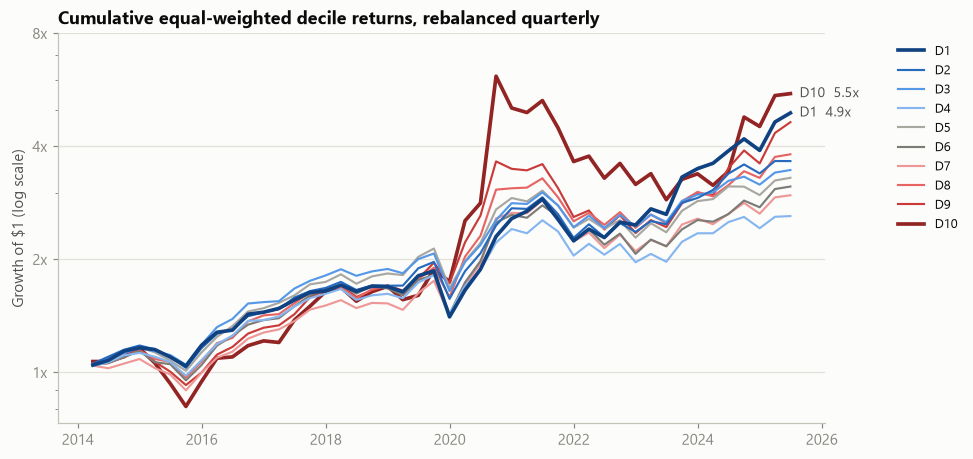

In [4]:
wealth = (1 + r3).cumprod()
fig, ax = plt.subplots(figsize=(9, 4.6))
for d in range(10, 0, -1):          # draw D1 last so it sits on top
    ax.plot(wealth.index, wealth[d], color=DECILE_COLORS[d], lw=2.4 if d in (1, 10) else 1.4,
            label=f"D{d}")
for d in (1, 10):
    ax.annotate(f"D{d}  {wealth[d].iloc[-1]:.1f}x", (wealth.index[-1], wealth[d].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color=INK2, fontsize=9)
ax.set_yscale("log")
ax.set_yticks([1, 2, 4, 8], ["1x", "2x", "4x", "8x"])
ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_ylabel("Growth of $1 (log scale)")
ax.set_title("Cumulative equal-weighted decile returns, rebalanced quarterly")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left", bbox_to_anchor=(1.08, 1), fontsize=8.5)
plt.show()

## 2. Which features did we end up using, and how important was each?

**Answer:** 16 features were tested (13 breadth + 3 size/value). Out-of-sample backward
elimination kept **15 at 12 months** (10 at 6 months). By mean |SHAP| the size/value
controls are the largest contributors; among breadth features, HHI, the exit rate and
aggregate institutional shares lead, followed by position-size dispersion.

SHAP size is not the same as out-of-sample usefulness: `hhi` has the largest SHAP value of the
breadth features but was dropped at 6 months (removing it did not lower OOS IC), along with
`new_position_rate`, `breadth_level`, `top5_share` and both ΔBreadth features. At 12 months only
`top5_share` was dropped. `delta_breadth`, the Chen–Hong–Stein predictor, has one of the two
smallest SHAP values.

*Caveats:* these values come from the README backtest, which uses the point-in-time size/value
features (Q7), point-in-time SEC issuer identities (Q10) and deadline-timed 13F snapshots. Which
features pruning drops is unstable: every pipeline fix so far has changed the list. Pruning is
shown for transparency; the factor in this notebook uses all 16 features, because pruning on the
evaluation folds would bias its IC upward.

*Method:* SHAP = mean |TreeSHAP| over out-of-sample test folds. A feature is dropped if
removing it (weakest first) does not reduce OOS mean IC.

In [5]:
r12m = json.load(open(TABLES / "backtest_results_12m.json"))
r6m = json.load(open(TABLES / "backtest_results_6m.json"))
q2 = pd.DataFrame({"Mean |SHAP| (12m)": pd.Series(r12m["shap_importance"])})
q2["Type"] = np.where(q2.index.isin(V.BASELINE_FEATURES), "size/value", "breadth")
q2["Kept (12m)"] = np.where(q2.index.isin(r12m["kept_features"]), "yes", "—")
q2["Kept (6m)"] = np.where(q2.index.isin(r6m["kept_features"]), "yes", "—")
q2 = q2.sort_values("Mean |SHAP| (12m)", ascending=False)
q2.index.name = "Feature"
q2[["Type", "Mean |SHAP| (12m)", "Kept (12m)", "Kept (6m)"]].style.format({"Mean |SHAP| (12m)": "{:.4f}"})

,Type,Mean |SHAP| (12m),Kept (12m),Kept (6m)
Feature,,,,
book_to_market,size/value,0.0426,yes,yes
earnings_yield,size/value,0.0306,yes,yes
log_market_cap,size/value,0.0293,yes,yes
hhi,breadth,0.0284,yes,—
exit_rate,breadth,0.0207,yes,yes
log_total_inst_shares,breadth,0.0194,yes,yes
position_size_dispersion,breadth,0.0194,yes,yes
top10_share,breadth,0.0185,yes,yes
new_position_rate,breadth,0.0184,yes,—


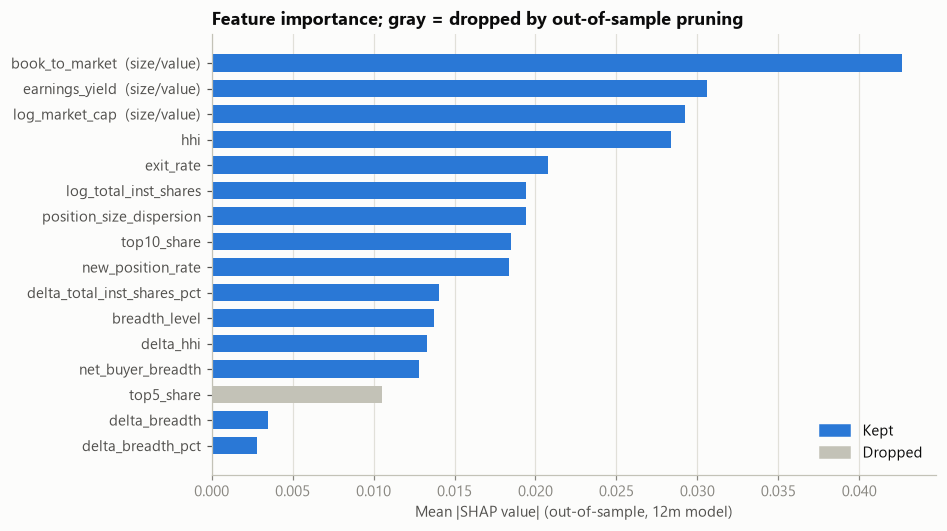

In [6]:
sh = q2.sort_values("Mean |SHAP| (12m)")
kept = sh["Kept (12m)"].eq("yes")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.barh(sh.index, sh["Mean |SHAP| (12m)"], color=np.where(kept, BLUE, AXIS), height=0.7)
ax.set_yticks(range(len(sh)), [f"{f}  (size/value)" if t == "size/value" else f
                               for f, t in zip(sh.index, sh["Type"])])
ax.tick_params(axis="y", colors=INK2)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("Mean |SHAP value| (out-of-sample, 12m model)")
ax.set_title("Feature importance; gray = dropped by out-of-sample pruning")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=AXIS)],
          labels=["Kept", "Dropped"], loc="lower right")
plt.show()

**What the breadth features measure** (in order of SHAP rank)

Each one is computed per stock from two consecutive quarterly 13F snapshots: this quarter (*p*) and last quarter (*p−1*). A "holder" is a 13F manager with a long, non-option position in the stock, and position sizes are share counts, not dollar value. The change features (exits, new positions, net buyers and the deltas) count only *continuing* managers, those that filed in both quarters, so a manager missing from one snapshot does not look as if it sold everything and bought it back.

- **`hhi`**: the Herfindahl index of holders' share weights (the sum of each holder's squared share of institutional shares). It is near 0 when ownership is spread out and 1 when a single holder owns everything.
- **`exit_rate`**: the number of last quarter's continuing holders that sold out completely, divided by last quarter's continuing-holder count.
- **`log_total_inst_shares`**: the log of total shares held by all 13F filers this quarter, which measures the overall scale of institutional ownership.
- **`position_size_dispersion`**: the standard deviation of log position sizes across the stock's holders. A high value means a mix of very large and very small stakes; a low value means holders own similar amounts.
- **`top10_share`**: the fraction of institutional shares held by the 10 largest holders. It is a simple measure of how concentrated ownership is.
- **`new_position_rate`**: the number of continuing holders that are new to the stock this quarter, divided by this quarter's continuing-holder count.
- **`delta_total_inst_shares_pct`**: the percentage change in shares held by continuing managers from *p−1* to *p*.
- **`breadth_level`**: the stock's holder count divided by the number of 13F managers that filed this quarter, i.e. the fraction of all institutions that own the stock.
- **`delta_hhi`**: the change in HHI among continuing managers from last quarter. A positive value means ownership became more concentrated.
- **`net_buyer_breadth`**: the number of continuing holders that increased their position minus those that cut it, divided by this quarter's continuing-holder count. It shows whether existing holders are, on balance, buying or selling.
- **`top5_share`**: the same as `top10_share`, but for the 5 largest holders.
- **`delta_breadth`**: the change in the number of continuing managers holding the stock, divided by the number of continuing managers. This is the Chen–Hong–Stein (2002) breadth signal.
- **`delta_breadth_pct`**: the same change divided by last quarter's continuing-holder count, so it measures proportional rather than absolute change.

*Size/value controls:* `log_market_cap` = log(as-traded price × SEC shares outstanding); `book_to_market` = book equity ÷ market cap; `earnings_yield` = trailing annual net income ÷ market cap. All three are measured at the formation date (Q7).

## 3. Is the breadth factor just a momentum proxy?

**Answer: no.** The factor's cross-sectional rank correlation with 12-1 momentum is about
zero (+0.05; +0.11 for the breadth-only model). After stripping momentum out of the score each
quarter, about 90% of the IC remains (0.069 → 0.063 for the factor, 0.065 → 0.060 for breadth-only),
all with t > 5. Momentum itself had essentially no 12-month IC in this sample (0.007).

**Size is the bigger overlap, but it does not explain the signal.** The breadth-only score has a
0.51 rank correlation with point-in-time market cap, since more institutional holders goes with
bigger companies. On names with a trustworthy cap, its IC falls from 0.057 to 0.038 (t 3.5;
Newey-West t 2.3) once size is removed. About two-thirds of the breadth-only score's IC is
therefore independent of size, in line with breadth's +0.020 increment over the size/value
baseline on those names (Q9).

*Method:* 12-1 momentum = return from 12 months to 1 month before formation, using only
prices on or before those dates. "Neutralised" = residual of the score's rank regressed on the
control's rank, per quarter. Each comparison uses the same stocks before and after.

In [7]:
m = vp.dropna(subset=["mom_12_1"]).copy()
for col in ("score_full", "score_breadth"):
    m[col + "_xmom"] = V.neutralize(m, col, ["mom_12_1"])

def avg_corr(df, a, b):
    return df.groupby("period").apply(lambda g: stats.spearmanr(g[a], g[b])[0]).mean()

rows = {
    "12-1 momentum": ("mom_12_1", np.nan),
    "Factor (breadth + size/value)": ("score_full", avg_corr(m, "score_full", "mom_12_1")),
    "Factor, momentum-neutral": ("score_full_xmom", np.nan),
    "Breadth-only model": ("score_breadth", avg_corr(m, "score_breadth", "mom_12_1")),
    "Breadth-only, momentum-neutral": ("score_breadth_xmom", np.nan),
}
q3 = pd.DataFrame({name: {**ic_summary(rank_ic(m, col, "fwd_ret_12m")), "Corr. with momentum": c}
                   for name, (col, c) in rows.items()}).T
q3 = q3.rename(columns={"mean_ic": "Mean IC", "t_stat": "t-stat", "icir": "ICIR",
                        "hit_rate": "% quarters IC > 0"})
q3 = q3[["Mean IC", "t-stat", "ICIR", "% quarters IC > 0", "Corr. with momentum"]]
q3.index.name = "Signal (12m forward return)"

# Size check for the breadth-only score, on names with a trustworthy point-in-time cap.
z = vp[vp["cap_ok"]].copy()
z["log_cap"] = np.log(z["market_cap"])
z["breadth_xsize"] = V.neutralize(z, "score_breadth", ["log_cap"])
b, bx = (ic_summary(rank_ic(z, c, "fwd_ret_12m")) for c in ("score_breadth", "breadth_xsize"))
print(f"Breadth-only vs size: rank corr {avg_corr(z, 'score_breadth', 'log_cap'):.2f}; "
      f"IC {b['mean_ic']:.3f} -> {bx['mean_ic']:.3f} after removing size (t {bx['t_stat']:.1f}), "
      f"on {len(z):,} stock-quarters with a sane cap")
q3.style.format({"Mean IC": "{:.3f}", "t-stat": "{:.1f}", "ICIR": "{:.2f}",
                 "% quarters IC > 0": "{:.0%}", "Corr. with momentum": "{:+.2f}"}, na_rep="")

Breadth-only vs size: rank corr 0.51; IC 0.057 -> 0.038 after removing size (t 3.5), on 102,530 stock-quarters with a sane cap


,Mean IC,t-stat,ICIR,% quarters IC > 0,Corr. with momentum
Signal (12m forward return),,,,,
12-1 momentum,0.007,0.4,0.05,59%,
Factor (breadth + size/value),0.069,5.7,0.84,80%,+0.05
"Factor, momentum-neutral",0.063,5.4,0.79,80%,
Breadth-only model,0.065,5.4,0.80,78%,+0.11
"Breadth-only, momentum-neutral",0.060,5.4,0.79,78%,


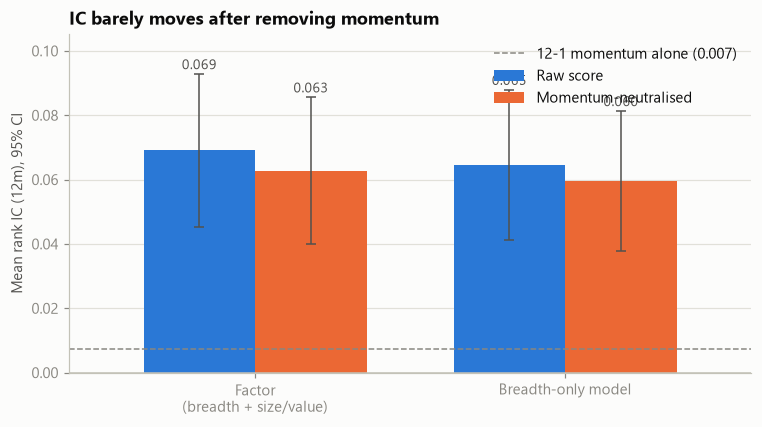

In [8]:
def ci95(col):
    ic = rank_ic(m, col, "fwd_ret_12m")
    return ic.mean(), 1.96 * ic.std(ddof=1) / np.sqrt(len(ic))

groups = [("Factor\n(breadth + size/value)", "score_full"), ("Breadth-only model", "score_breadth")]
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(groups)); w = 0.36
for k, (lab, suffix, color) in enumerate([("Raw score", "", BLUE), ("Momentum-neutralised", "_xmom", ORANGE)]):
    vals = [ci95(col + suffix) for _, col in groups]
    bars = ax.bar(x + (k - 0.5) * w, [v for v, _ in vals], w, yerr=[e for _, e in vals],
                  color=color, label=lab, error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 3})
    for bar, (v, e) in zip(bars, vals):
        ax.annotate(f"{v:.3f}", (bar.get_x() + bar.get_width() / 2, v + e), xytext=(0, 3),
                    textcoords="offset points", ha="center", color=INK2, fontsize=9)
ax.set_xlim(-0.6, len(groups) - 0.4)
mom_ic = rank_ic(m, "mom_12_1", "fwd_ret_12m").mean()
ax.axhline(mom_ic, color=MUTED, ls="--", lw=1, label=f"12-1 momentum alone ({mom_ic:.3f})")
ax.axhline(0, color=AXIS, lw=1)
ax.set_ylim(0, ax.get_ylim()[1] * 1.08)
ax.set_xticks(x, [g for g, _ in groups])
ax.set_ylabel("Mean rank IC (12m), 95% CI")
ax.set_title("IC barely moves after removing momentum")
ax.legend(loc="upper right")
plt.show()

## 4. Does the factor work better in some regimes than others?

**Answer: it worked better when rates were rising, but the evidence is weak.** IC averaged 0.095
in the 25 quarters where the 10-year Treasury yield was higher than a year earlier, versus 0.042
in the 21 quarters where it was lower (Welch p ≈ 0.05). The level of rates (above vs below the
sample median: 0.085 vs 0.057) makes no clear difference (p ≈ 0.3). Treat the trend result as
suggestive at best: adjacent quarters' 12-month returns overlap, so the p-value overstates the
evidence, and falling-rate quarters cluster in three episodes (mid-2014–2016, 2019–early 2021 and
late 2024). The factor's average IC was positive in every bucket.

*Method:* 10-year yield (`^TNX`) observed on or before each formation date. This is a
descriptive split, not a timing signal.

In [9]:
fd = vp.groupby("period")["formation_date"].first()
regimes = V.rate_regimes(fd, V.load_macro_series(cfg, "^TNX")).set_index("formation_date")
ics = pd.DataFrame({"Factor": ic_factor.values,
                    "Breadth-only": rank_ic(vp, "score_breadth", "fwd_ret_12m").values},
                   index=pd.to_datetime(fd.loc[ic_factor.index].values)).join(regimes)

rows = []
for col, order in [("trend", ["Rising rates", "Falling rates"]), ("level", ["High rates", "Low rates"])]:
    for lab in order:
        g = ics[ics[col] == lab]
        rows.append({"Split": "Trend (vs 12m ago)" if col == "trend" else "Level (vs median)",
                     "Regime": lab, "Quarters": len(g),
                     "Mean IC (factor)": g["Factor"].mean(),
                     "t-stat": g["Factor"].mean() / (g["Factor"].std(ddof=1) / np.sqrt(len(g))),
                     "Mean IC (breadth-only)": g["Breadth-only"].mean()})
q4 = pd.DataFrame(rows).set_index(["Split", "Regime"])
for col, (a, b) in [("trend", ("Rising rates", "Falling rates")), ("level", ("High rates", "Low rates"))]:
    p = stats.ttest_ind(ics.loc[ics[col] == a, "Factor"], ics.loc[ics[col] == b, "Factor"],
                        equal_var=False).pvalue
    print(f"{a} vs {b}: difference in mean IC, Welch p = {p:.3f}")
q4.style.format({"Mean IC (factor)": "{:.3f}", "t-stat": "{:.1f}", "Mean IC (breadth-only)": "{:.3f}"})

Rising rates vs Falling rates: difference in mean IC, Welch p = 0.049
High rates vs Low rates: difference in mean IC, Welch p = 0.276


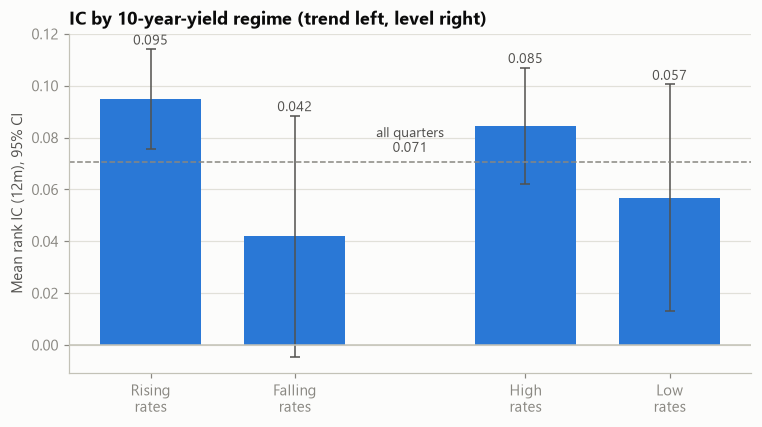

In [10]:
labels = [r for _, r in q4.index]
means = q4["Mean IC (factor)"].to_numpy()
errs = 1.96 * means / q4["t-stat"].to_numpy()           # 1.96 x standard error
pos = np.array([0, 1, 2.6, 3.6])
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(pos, means, 0.7, yerr=errs, color=BLUE,
              error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 3})
for bar, v, e in zip(bars, means, errs):
    ax.annotate(f"{v:.3f}", (bar.get_x() + bar.get_width() / 2, v + e), xytext=(0, 3),
                textcoords="offset points", ha="center", color=INK2, fontsize=9)
ax.axhline(ic_factor.mean(), color=MUTED, ls="--", lw=1)
ax.annotate(f"all quarters\n{ic_factor.mean():.3f}", (1.8, ic_factor.mean()), xytext=(0, 4),
            textcoords="offset points", ha="center", va="bottom", color=INK2, fontsize=9)
ax.axhline(0, color=AXIS, lw=1)
ax.set_xticks(pos, [l.replace(" ", "\n") for l in labels])
ax.set_ylabel("Mean rank IC (12m), 95% CI")
ax.set_title("IC by 10-year-yield regime (trend left, level right)")
plt.show()

## 5. Are the deciles stable from quarter to quarter?

**Answer: the extremes are sticky, the middle churns.** D1 keeps 63% of its names into the
next quarter and D10 keeps 54%, versus about 20% for the middle deciles (10% would be pure chance).
Even so, about 110 of D1's ~294 names are replaced every quarter (~38% one-way turnover,
~150% a year), so trading costs would materially reduce a live version of this factor.
Most moves are to a neighbouring decile; fewer than 1% of names jump from one end to the other.

*Notes:* "Left universe" = no longer scored next quarter (fewer than 5 holders, delisted, or
merged). Four of the 45 transitions cross a CV-fold boundary, where a different model scores
the next quarter; D1 retention there is 39% versus 65% within a fold, so the averages slightly
overstate true turnover.

In [11]:
flows = V.decile_flows(vp)
g = flows.groupby("decile")
q5 = pd.DataFrame({
    "Avg names": g["size"].mean(),
    "Avg entering / qtr": g["entered"].mean(),
    "Avg leaving / qtr": g["left"].mean(),
    "Stayed in decile": g["retained"].sum() / g["prior_size"].sum(),
})
q5.index = [f"D{d}" for d in q5.index]
q5.index.name = "Decile"
for cross, lab in [(False, "within a CV fold"), (True, "across a CV-fold boundary")]:
    f = flows[(flows.cross_fold == cross) & (flows.decile == 1)]
    print(f"D1 retention {lab}: {f.retained.sum() / f.prior_size.sum():.0%} "
          f"({f.period.nunique()} transitions)")
q5.style.format({"Avg names": "{:.0f}", "Avg entering / qtr": "{:.0f}",
                 "Avg leaving / qtr": "{:.0f}", "Stayed in decile": "{:.0%}"})

D1 retention within a CV fold: 65% (41 transitions)
D1 retention across a CV-fold boundary: 39% (4 transitions)


,Avg names,Avg entering / qtr,Avg leaving / qtr,Stayed in decile
Decile,,,,
D1,294,113,108,63%
D2,293,195,190,34%
D3,293,219,214,26%
D4,293,230,225,22%
D5,293,234,229,20%
D6,293,237,232,19%
D7,293,235,230,20%
D8,293,223,218,24%
D9,293,206,201,30%


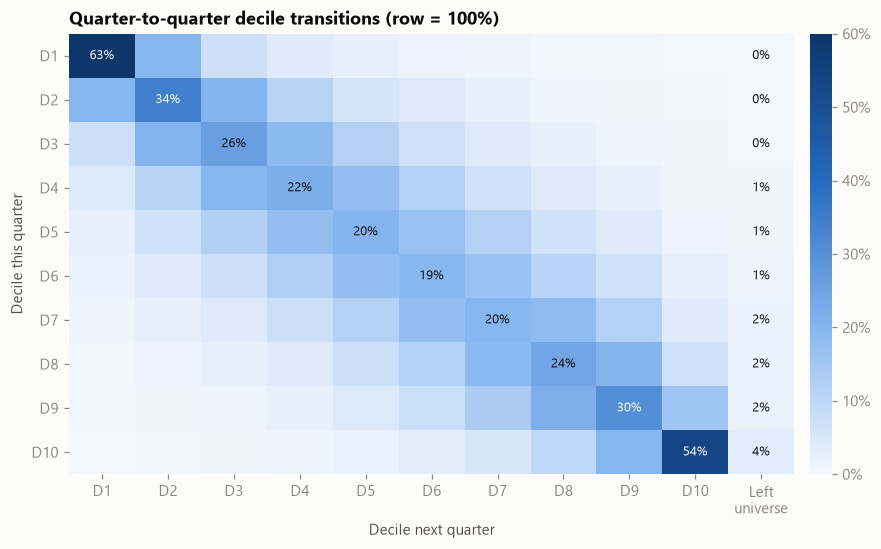

In [12]:
tm = V.transition_matrix(vp)
cmap = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#86b6ef", "#256abf", "#0d366b"])
fig, ax = plt.subplots(figsize=(9, 5.2))
im = ax.imshow(tm.to_numpy(), cmap=cmap, vmin=0, vmax=0.6, aspect="auto")
ax.set_xticks(range(tm.shape[1]), [f"D{c}" if c != "Left universe" else "Left\nuniverse" for c in tm.columns])
ax.set_yticks(range(tm.shape[0]), [f"D{r}" for r in tm.index])
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
for i in range(tm.shape[0]):               # label the diagonal and the exit column only
    for j in (i, tm.shape[1] - 1):
        v = tm.iat[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8.5,
                color="white" if v > 0.3 else INK)
ax.set_xlabel("Decile next quarter")
ax.set_ylabel("Decile this quarter")
ax.set_title("Quarter-to-quarter decile transitions (row = 100%)")
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02, format=PCT)
cb.outline.set_visible(False)
cb.ax.tick_params(colors=MUTED)
plt.show()

## 6. Cap-weighted vs equal-weighted top-minus-bottom decile

**Answer: the long-short doesn't work either way; the long leg does, narrowly.** A quarterly
D1 − D10 portfolio loses about 6% a year equal-weighted, with 34% volatility (not significant).
On the names with a trustworthy market cap, the equal-weighted version loses about 8% a year
and the cap-weighted one about 2%. In every version, though, D1 beats its own universe (see the
D1 and universe columns): by 1–2 points a year equal-weighted, but only 0.4 cap-weighted.
The short leg is the problem: D10 is mostly micro-caps (median $0.15bn) whose occasional
explosive rallies, such as the late-2020 meme and crypto run, overwhelm a short position.
Survivorship bias in the free price data also flatters those micro-caps.
The usable edge is **long-only**, not market-neutral.

*Assumptions:* dollar-neutral, long D1 and short D10 (deciles formed on the full universe),
rebalanced quarterly with a 3-month hold, gross of trading and borrow costs. Cumulative
returns are summed rather than compounded (a short leg can lose more than 100% in a quarter).
Cap weights use formation-date **as-traded** price × SEC-XBRL shares outstanding, restricted to
caps that pass the checks in Q7–Q8 (77% of stock-quarters). Equal-weighted results are shown both
on all names and on that same subset, so the comparison is like-for-like.

In [13]:
clean = vp[vp["cap_ok"]]
def univ(df, weight=None):
    d = df.dropna(subset=["fwd_ret_3m"] + ([weight] if weight else []))
    if weight is None:
        return d.groupby("period")["fwd_ret_3m"].mean()
    return (d["fwd_ret_3m"] * d[weight]).groupby(d["period"]).sum() / d[weight].groupby(d["period"]).sum()

variants = {
    "Equal-weighted, all names": (V.decile_returns(vp, "fwd_ret_3m"), univ(vp)),
    "Equal-weighted, sane-cap names": (V.decile_returns(clean, "fwd_ret_3m"), univ(clean)),
    "Cap-weighted, sane-cap names": (V.decile_returns(clean, "fwd_ret_3m", weight_col="market_cap"),
                                     univ(clean, "market_cap")),
}
ls = {k: d[1] - d[10] for k, (d, _) in variants.items()}
q6 = pd.DataFrame({k: {**V.long_short_stats(ls[k]),
                       "Long D1 (ann.)": d[1].mean() * 4,
                       "Universe (ann.)": u.mean() * 4,
                       "Short D10 (ann.)": d[10].mean() * 4} for k, (d, u) in variants.items()}).T
q6 = q6[["Ann. return", "Ann. vol", "Sharpe", "t-stat", "Worst quarter", "% quarters > 0",
         "Long D1 (ann.)", "Universe (ann.)", "Short D10 (ann.)"]]
q6.index.name = "D1 − D10, quarterly rebalance"
print("Median point-in-time cap: D1", money(clean.loc[clean.decile == 1, "market_cap"].median()),
      "| D10", money(clean.loc[clean.decile == 10, "market_cap"].median()))
q6.style.format({c: "{:.1%}" for c in q6.columns if c not in ("Sharpe", "t-stat")} |
                {"Sharpe": "{:.2f}", "t-stat": "{:.1f}"})

Median point-in-time cap: D1 $9.3bn | D10 $150.2m


,Ann. return,Ann. vol,Sharpe,t-stat,Worst quarter,% quarters > 0,Long D1 (ann.),Universe (ann.),Short D10 (ann.)
"D1 − D10, quarterly rebalance",,,,,,,,,
"Equal-weighted, all names",-5.9%,34.6%,-0.17,-0.6,-95.4%,60.9%,15.7%,13.5%,21.5%
"Equal-weighted, sane-cap names",-8.5%,38.5%,-0.22,-0.7,-105.7%,60.9%,15.7%,14.4%,24.2%
"Cap-weighted, sane-cap names",-2.1%,24.0%,-0.09,-0.3,-60.4%,52.2%,13.4%,13.0%,15.5%


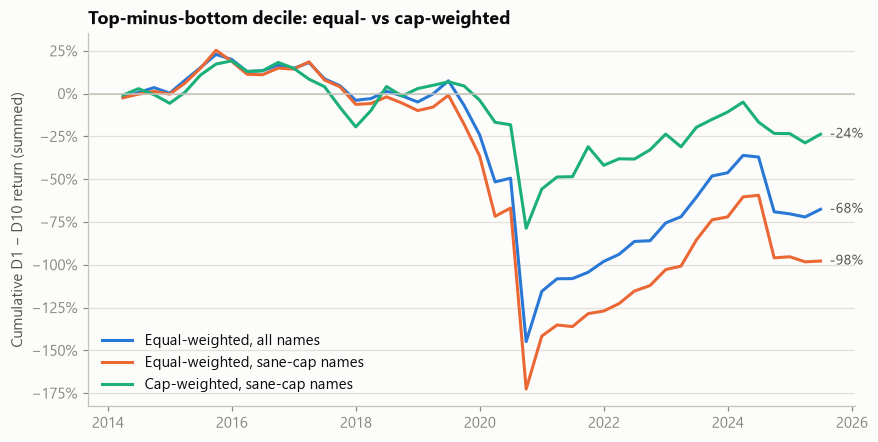

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.4))
cums = {name: r.cumsum() for name, r in ls.items()}
for (name, c), color in zip(cums.items(), [BLUE, ORANGE, AQUA]):
    ax.plot(c.index, c.values, color=color, label=name)
# End labels, nudged apart when two lines finish close together.
ends = sorted((c.iloc[-1], name) for name, c in cums.items())
span = max(ends)[0] - min(ends)[0]
for k, (v, name) in enumerate(ends):
    close_below = k > 0 and v - ends[k - 1][0] < 0.08 * span
    close_above = k < len(ends) - 1 and ends[k + 1][0] - v < 0.08 * span
    dy = -6 if close_above else (6 if close_below else 0)
    ax.annotate(f"{v:+.0%}", (cums[name].index[-1], v), xytext=(6, dy),
                textcoords="offset points", va="center", color=INK2, fontsize=9)
ax.axhline(0, color=AXIS, lw=1)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylabel("Cumulative D1 − D10 return (summed)")
ax.set_title("Top-minus-bottom decile: equal- vs cap-weighted")
ax.legend(loc="lower left")
plt.show()

## 7. Are the size/value inputs point-in-time?

**Answer: now yes — but originally they were not, and that was a real look-ahead.** Phase 4
first computed market cap as yfinance's *adjusted* close × the XBRL share count. Adjusted prices
are rescaled backwards for every later split and dividend, so a stock that later splits 20-for-1
looks 20× smaller on earlier dates. Because stocks split *after* rising, future winners looked
small and cheap at formation. 10% of stock-quarters had caps understated by at least 1.5×, and 5%
by at least 2× (e.g. AMZN 20× and NVDA 40× at end-2019). The understatement alone predicts
12-month returns (IC ≈ 0.089).

**Fix and impact:** Phase 4 now builds `log_market_cap`, `book_to_market` and `earnings_yield`
from as-traded prices (and drops caps that fail the Q8 check). The table replays the old
features next to the current ones on identical folds, both with point-in-time SEC issuer
identities (Q10) and deadline-timed 13F snapshots: the baseline IC falls from 0.060 to 0.049 and
the full model's from 0.077 to 0.0706, while the **incremental IC from breadth rises (+0.017 →
+0.022)**. The look-ahead had flattered the size/value controls, not the breadth signal. (When the
bug was found, before the Q10 and snapshot-timing fixes, the same replay moved the full model from
0.072 to 0.0644.)

*Method:* as-traded price = yfinance close (not dividend-adjusted, still split-adjusted)
multiplied by all splits after the date, using the last close on or before the formation date.
The "look-ahead" column rebuilds the old features exactly (adjusted close × the same share
count, no share-count check) and is kept only for this comparison.

In [15]:
ic_tab = pd.DataFrame({
    "Look-ahead (pre-fix)": [ic_summary(rank_ic(vp, c, "fwd_ret_12m"))["mean_ic"]
                             for c in ("score_baseline_lookahead", "score_full_lookahead")],
    "Point-in-time (Phase 4 now)": [ic_summary(rank_ic(vp, c, "fwd_ret_12m"))["mean_ic"]
                                    for c in ("score_baseline", "score_full")],
}, index=["Size/value baseline", "Full model (breadth + size/value)"])
ic_tab.loc["Incremental IC from breadth"] = ic_tab.iloc[1] - ic_tab.iloc[0]
ic_tab.index.name = "Mean rank IC, 12m"
leak = vp.dropna(subset=["market_cap", "market_cap_lookahead"]).assign(
    understated=lambda d: np.log(d["market_cap"] / d["market_cap_lookahead"]))
lk = ic_summary(rank_ic(leak, "understated", "fwd_ret_12m"))
print(f"IC of the understatement itself vs 12m return: {lk['mean_ic']:.3f} (t {lk['t_stat']:.1f})")
display(ic_tab.style.format("{:.4f}"))

ex = vp[(vp.period == pd.Timestamp("2019-12-31")) & vp.ticker.isin(["AAPL", "AMZN", "NVDA", "TSLA", "NFLX", "MSFT"])]
ex = ex.assign(ratio=ex["market_cap"] / ex["market_cap_lookahead"]).sort_values("ratio", ascending=False)
pd.DataFrame({"Ticker": ex["ticker"], "Look-ahead cap (pre-fix)": ex["market_cap_lookahead"].map(money),
              "Point-in-time cap": ex["market_cap"].map(money),
              "Understated by": ex["ratio"].map("{:.1f}x".format)}).style.hide(axis="index")     .set_caption(f"Formation {ex.formation_date.iloc[0]:%Y-%m-%d} (period 2019-Q4)")

IC of the understatement itself vs 12m return: 0.089 (t 4.2)


,Look-ahead (pre-fix),Point-in-time (Phase 4 now)
"Mean rank IC, 12m",,
Size/value baseline,0.0602,0.0485
Full model (breadth + size/value),0.0767,0.0706
Incremental IC from breadth,0.0165,0.0221


Ticker,Look-ahead cap (pre-fix),Point-in-time cap,Understated by
NVDA,$4.5bn,$181.5bn,40.3x
AMZN,$53.7bn,$1.1T,20.0x
TSLA,$10.4bn,$155.7bn,15.0x
NFLX,$17.0bn,$170.2bn,10.0x
AAPL,$336.7bn,$1.4T,4.1x
MSFT,$1.3T,$1.4T,1.1x


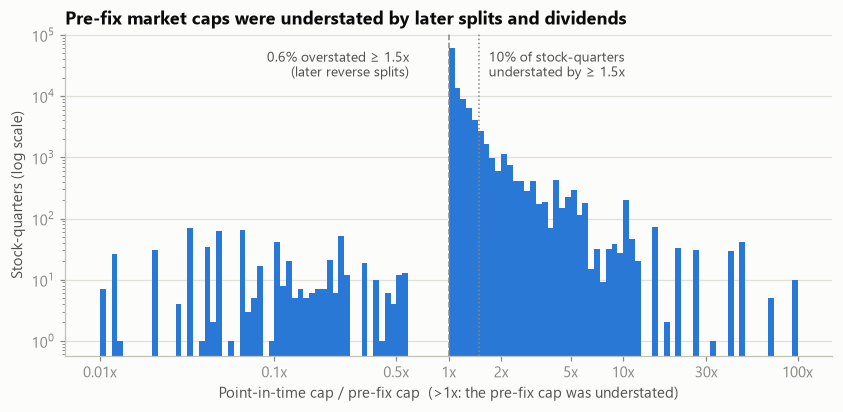

In [16]:
both = vp.dropna(subset=["market_cap", "market_cap_lookahead"])
ratio = np.log10(both["market_cap"] / both["market_cap_lookahead"]).clip(-2, 2)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(ratio, bins=120, color=BLUE)
ax.set_yscale("log")
ax.axvline(0, color=MUTED, ls="--", lw=1)
ax.axvline(np.log10(1.5), color=MUTED, ls=":", lw=1)
share = (both["market_cap"] / both["market_cap_lookahead"] >= 1.5).mean()
ax.annotate(f"{share:.0%} of stock-quarters\nunderstated by ≥ 1.5x", (np.log10(1.5), ax.get_ylim()[1]),
            xytext=(6, -28), textcoords="offset points", color=INK2, fontsize=9)
over = (both["market_cap"] / both["market_cap_lookahead"] <= 1 / 1.5).mean()
ax.annotate(f"{over:.1%} overstated ≥ 1.5x\n(later reverse splits)", (np.log10(1 / 1.5), ax.get_ylim()[1]),
            xytext=(-6, -28), textcoords="offset points", ha="right", color=INK2, fontsize=9)
ticks = [0.01, 0.1, 0.5, 1, 2, 5, 10, 30, 100]
ax.set_xticks(np.log10(ticks), [f"{t:g}x" for t in ticks])
ax.set_xlabel("Point-in-time cap / pre-fix cap  (>1x: the pre-fix cap was understated)")
ax.set_ylabel("Stock-quarters (log scale)")
ax.set_title("Pre-fix market caps were understated by later splits and dividends")
plt.show()

## 8. Are the SEC share counts sane?

**Answer: mostly, with a tail of bad ones.** 3.1% of stock-quarters with a share count (572 tickers)
fail a consistency check against 13F holdings. Two causes are visible. **ADRs**: the price is
per ADR but XBRL reports *ordinary* shares, so issuers like Toyota, HSBC, Vodafone and Diageo come
out several times too large (Toyota at about $2.5T). **Filing scale errors**: e.g. BTI implies a
cap of about $90,000 *trillion*, and some issuers, such as FOXA, come out implausibly small. Phase 4 now
applies this check: these rows get missing size/value features (LightGBM treats them as
unknown rather than wrong), and Q6 excludes them.

*Check:* the implied institutional-ownership ratio (13F shares held ÷ XBRL shares outstanding)
should lie between 1% and 300%, because 13F holdings independently count the same shares.
Point-in-time caps above $6T are also rejected. The 1% floor is deliberately conservative: it
also drops some foreign issuers whose caps are roughly right but whose shares sit mostly with
holders who don't file 13Fs.

In [17]:
lo, hi = V.IO_RATIO_BOUNDS
has = vp.dropna(subset=["io_ratio"])
bad = has[~has["io_ratio"].between(lo, hi) | (has["market_cap"] > V.MCAP_MAX)]
print(f"{len(bad):,} of {len(has):,} stock-quarters with a share count fail ({len(bad) / len(has):.1%}), "
      f"{bad.ticker.nunique()} tickers")
worst = (bad.assign(dist=np.abs(np.log10(bad["io_ratio"])))
            .sort_values("dist", ascending=False).drop_duplicates("ticker").head(6))
adrs = (bad[bad.ticker.isin(["TM", "HSBC", "VOD", "DEO"])]
        .sort_values("period", ascending=False).drop_duplicates("ticker"))   # latest flagged quarter
show = pd.concat([worst, adrs])
pd.DataFrame({"Ticker": show["ticker"], "Quarter": show["period"].dt.strftime("%Y-%m"),
              "Implied cap": show["market_cap"].fillna(show["market_cap_lookahead"]).map(money),
              "13F shares / XBRL shares": show["io_ratio"].map("{:.2g}".format)}).style.hide(axis="index")

3,325 of 107,247 stock-quarters with a share count fail (3.1%), 573 tickers


Ticker,Quarter,Implied cap,13F shares / XBRL shares
FOXA,2020-09,$28,3.5e+08
FOX,2020-09,$28,1.5e+08
BTI,2020-12,"$90,498.2T",4.6e-08
CUBI,2014-12,$22,2e+07
CIA,2020-12,$6,1.3e+07
IOVA,2021-06,$318,1.1e+07
VOD,2025-06,$336.3bn,0.0071
HSBC,2025-06,$1.1T,0.0039
TM,2025-06,$2.5T,0.0016


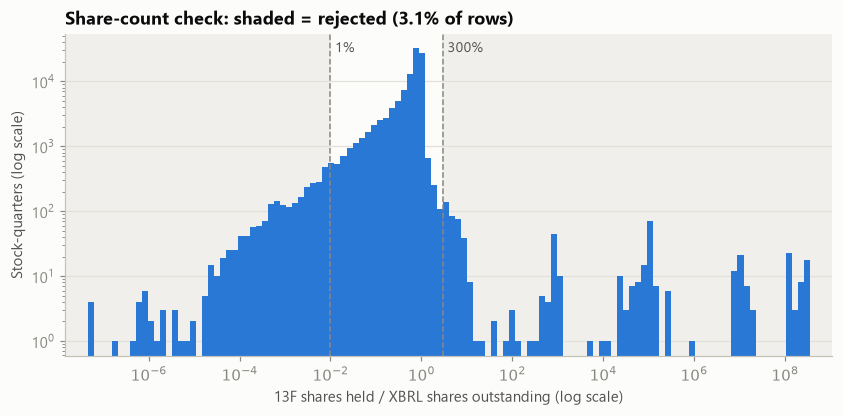

In [18]:
x = np.log10(has["io_ratio"].clip(1e-9, 1e9))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axvspan(x.min() - 0.5, np.log10(lo), color="#f0efec", zorder=0)
ax.axvspan(np.log10(hi), x.max() + 0.5, color="#f0efec", zorder=0)
ax.hist(x, bins=120, color=BLUE)
ax.set_yscale("log")
for b, lab in [(lo, f"{lo:.0%}"), (hi, f"{hi:.0%}")]:
    ax.axvline(np.log10(b), color=MUTED, ls="--", lw=1)
    ax.annotate(lab, (np.log10(b), ax.get_ylim()[1]), xytext=(3, -12), textcoords="offset points",
                color=INK2, fontsize=9)
ax.set_xlim(x.min() - 0.5, x.max() + 0.5)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"$10^{{{v:.0f}}}$"))
ax.set_xlabel("13F shares held / XBRL shares outstanding (log scale)")
ax.set_ylabel("Stock-quarters (log scale)")
ax.set_title(f"Share-count check: shaded = rejected ({len(bad) / len(has):.1%} of rows)")
plt.show()

## 9. Do the breadth features work better on large caps or small caps?

**Answer: the factor works on smaller stocks, and breadth adds to size/value at every size, but in
large caps that only lifts a wrong-way baseline to about zero.** Each quarter, names with a
trustworthy point-in-time cap are split into size quintiles. The factor's IC is small in the three
largest quintiles (0.005, 0.027 and 0.001, at median caps of \$30bn, \$5.1bn and \$1.7bn) and large
only in the two smallest: 0.074 and 0.129, at median caps of \$0.47bn and \$80m. The size/value
model alone does most of that (0.042 and 0.115), and it is *negative* in the three largest
quintiles (−0.027, −0.001 and −0.038).

Breadth's own contribution, its increment over the size/value model, is positive in every
quintile: +0.031, +0.028, +0.040, +0.032 and +0.014 from largest to smallest (Newey-West t 2.3,
2.4, 4.8, 2.8 and 1.1), and positive in 67–80% of quarters. Models trained on each quintile alone
find smaller increments, clearest in the middle quintiles (+0.018 and +0.038 in Q2 and Q3, t 2.1
and 4.6), +0.007 (t 0.6) in the largest fifth and about zero in the smallest. With 10 tries some
t ≈ 2 results are expected by chance, but the Q3 result is not one of them. There is no size
gradient: the increment in the two smallest quintiles minus that in the two largest is −0.006
(Newey-West t −0.6).

**Two subset results:**
- **On names with a trustworthy cap, breadth adds as much as it does overall.** The factor's IC
  there is 0.061 (Newey-West t 2.8) against 0.041 for size/value alone: an increment of +0.020
  (t 3.1), close to the pooled +0.022. Before the snapshot-timing fix this was +0.001 (t 0.1), and
  breadth's pooled increment had seemed to come only from names size/value cannot see.
- **The 23% of names without a trustworthy cap** are mostly issuers with no usable SEC share count:
  companies that report shares by class (GOOGL, META, ABNB) and foreign filers (SHEL, BP), plus
  names that fail the Q8 check (V, MA, BRK/B). They have fewer holders (a median of 49 against 172).
  The size/value model cannot rank them, so the factor runs on breadth alone, with an IC of 0.065
  (Newey-West t 4.1) there. The pooled IC (0.071) is a little above the average of the two groups'
  own ICs (0.062): the model scores no-cap names lower, and they returned about 3.6 points less over
  12 months. Q10 breaks this down.

The practical reading is that breadth is a real increment over size/value across the size range,
clearest in mid caps (\$1–5bn). The factor's *level* of IC, though, sits in small caps, where
size/value already works, trading costs are highest and survivorship bias in the free price feed
flatters returns (Q6). In the largest names the combined score is close to uninformative.

*Method:* size quintiles are formed each quarter on the point-in-time market cap (Q7), using the 77%
of stock-quarters whose cap passes the Q8 check; Q1 is the largest. The "README model" columns
evaluate the existing out-of-sample scores inside each quintile. The "bucket-trained" columns refit
the full and size/value models on that quintile alone, using the same purged & embargoed folds. The
increment is the paired per-quarter difference between full-model and size/value IC. All t-statistics
in this question are Newey-West (4 lags).

In [19]:
SIZE_LABELS = {1: "Q1 largest", 2: "Q2", 3: "Q3", 4: "Q4", 5: "Q5 smallest"}
sz = vp[vp["cap_ok"]].copy()
sz["size_q"] = V.assign_deciles(sz, "market_cap", n=5)          # 1 = largest cap, re-formed each quarter

def ic_row(g):
    full, base = (rank_ic(g, c, "fwd_ret_12m") for c in ("score_full", "score_baseline"))
    inc = (full - base).dropna()                                  # paired, per quarter
    return {"Full model IC": full.mean(), "t (full)": newey_west_t(full, 4),
            "Size/value IC": base.mean(), "Breadth increment": inc.mean(),
            "t (increment)": newey_west_t(inc, 4), "% qtrs increment > 0": (inc > 0).mean()}, inc

# (a) The README model's out-of-sample scores, evaluated inside each size bucket.
rows, global_inc = {}, {}
for q, lab in SIZE_LABELS.items():
    g = sz[sz["size_q"] == q]
    r, global_inc[q] = ic_row(g)
    rows[lab] = {"Names / qtr": g.groupby("period").size().mean(), "Median cap": g["market_cap"].median(), **r}
for lab, g in [("All trustworthy-cap names", sz), ("No trustworthy cap", vp[~vp["cap_ok"]]),
               ("All names (README)", vp)]:
    rows[lab] = {"Names / qtr": g.groupby("period").size().mean(), **ic_row(g)[0]}

# (b) Full and size/value models refit on each size bucket alone (same purged folds and settings).
panel = pd.read_parquet(cfg.path("processed") / "model_panel.parquet")
panel = panel.merge(sz[["period", "composite_figi", "size_q"]], on=["period", "composite_figi"])
cv = PurgedKFold(n_splits=int(cfg.raw["cv"]["n_splits"]), horizon_months=12,
                 embargo_days=int(cfg.raw["cv"]["embargo_days"]))
own_inc = {}
for q, lab in SIZE_LABELS.items():
    g = panel[panel["size_q"] == q]
    full, base = (rank_ic(run_cv_predictions(g, feats, "fwd_ret_12m", cv), "pred", "fwd_ret_12m")
                  for feats in (V.FULL_FEATURES, V.BASELINE_FEATURES))
    own_inc[q] = (full - base).dropna()
    rows[lab] |= {"Increment, bucket-trained": own_inc[q].mean(),
                  "t (bucket-trained)": newey_west_t(own_inc[q], 4)}

q9 = pd.DataFrame(rows).T
q9.index.name = "Size quintile (point-in-time cap)"
for name, inc in [("README model", global_inc), ("bucket-trained", own_inc)]:
    d = ((inc[4] + inc[5]) / 2 - (inc[1] + inc[2]) / 2).dropna()
    print(f"Breadth increment, two smallest minus two largest quintiles ({name}): "
          f"{d.mean():+.4f} (Newey-West t {newey_west_t(d, 4):.1f})")

# Pooled IC vs the two groups' own ICs: the gap is ranking the no-cap names against the rest.
n = vp.groupby(["period", "cap_ok"]).size()
within = (rank_ic(vp, FACTOR, "fwd_ret_12m", by=["period", "cap_ok"]) * n).groupby(level=0).sum() / n.groupby(level=0).sum()
ret = vp.groupby(["period", "cap_ok"])["fwd_ret_12m"].mean().unstack().mean()
print(f"All names: pooled IC {ic_factor.mean():.3f} vs average within-group IC {within.mean():.3f}; "
      f"mean 12m return {ret[False]:.1%} without a trustworthy cap vs {ret[True]:.1%} with one")

q9.style.format({"Names / qtr": "{:.0f}", "Median cap": money, "Full model IC": "{:.3f}",
                 "Size/value IC": "{:.3f}", "Breadth increment": "{:+.3f}",
                 "Increment, bucket-trained": "{:+.3f}", "% qtrs increment > 0": "{:.0%}",
                 "t (full)": "{:.1f}", "t (increment)": "{:.1f}", "t (bucket-trained)": "{:.1f}"},
                na_rep="")

Breadth increment, two smallest minus two largest quintiles (README model): -0.0064 (Newey-West t -0.6)
Breadth increment, two smallest minus two largest quintiles (bucket-trained): +0.0014 (Newey-West t 0.1)


All names: pooled IC 0.071 vs average within-group IC 0.062; mean 12m return 12.3% without a trustworthy cap vs 15.8% with one


,Names / qtr,Median cap,Full model IC,t (full),Size/value IC,Breadth increment,t (increment),% qtrs increment > 0,"Increment, bucket-trained",t (bucket-trained)
Size quintile (point-in-time cap),,,,,,,,,,
Q1 largest,446,$29.6bn,0.005,0.2,-0.027,+0.031,2.3,80%,+0.007,0.6
Q2,446,$5.1bn,0.027,1.3,-0.001,+0.028,2.4,67%,+0.018,2.1
Q3,446,$1.7bn,0.001,0.1,-0.038,+0.040,4.8,76%,+0.038,4.6
Q4,446,$468.6m,0.074,2.6,0.042,+0.032,2.8,74%,+0.024,1.5
Q5 smallest,446,$80.0m,0.129,3.5,0.115,+0.014,1.1,72%,+0.003,0.2
All trustworthy-cap names,2229,,0.061,2.8,0.041,+0.020,3.1,80%,,
No trustworthy cap,683,,0.065,4.1,,,,,,
All names (README),2912,,0.071,3.6,0.049,+0.022,3.6,80%,,


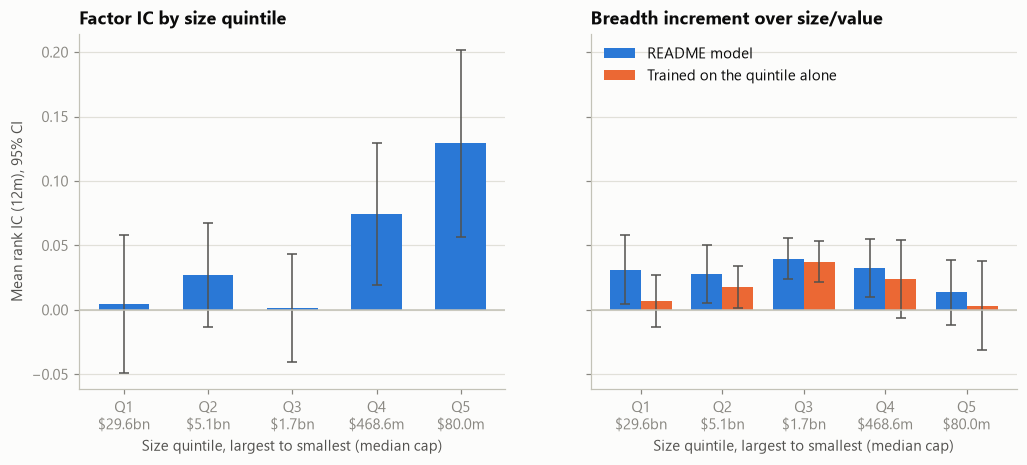

In [20]:
x = np.arange(1, 6)
quint = q9.loc[list(SIZE_LABELS.values())]
ticks = [f"Q{q}\n{money(m)}" for q, m in zip(x, quint["Median cap"])]

def ci(mean, t):
    return 1.96 * np.abs(mean / t)                                 # 1.96 x Newey-West standard error

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
ekw = {"ecolor": INK2, "elinewidth": 1, "capsize": 3}
ax1.bar(x, quint["Full model IC"], 0.6, yerr=ci(quint["Full model IC"], quint["t (full)"]),
        color=BLUE, error_kw=ekw)
ax1.set_title("Factor IC by size quintile")
ax1.set_ylabel("Mean rank IC (12m), 95% CI")
w = 0.38
for k, (col, t, lab, color) in enumerate([
        ("Breadth increment", "t (increment)", "README model", BLUE),
        ("Increment, bucket-trained", "t (bucket-trained)", "Trained on the quintile alone", ORANGE)]):
    ax2.bar(x + (k - 0.5) * w, quint[col], w, yerr=ci(quint[col], quint[t]), color=color,
            label=lab, error_kw=ekw)
ax2.set_title("Breadth increment over size/value")
ax2.legend(loc="upper left")
for ax in (ax1, ax2):
    ax.axhline(0, color=AXIS, lw=1)
    ax.set_xticks(x, ticks)
    ax.set_xlabel("Size quintile, largest to smallest (median cap)")
plt.show()

## 10. How much of the headline IC came from names with no size/value data?

**Answer: about 0.025 of the old 0.0644 headline came from ranking names without size/value data
below the rest. Much of that rested on a look-ahead in how Phase 4 found each issuer's SEC filings,
now fixed. Of today's 0.0706, only 0.0075 is between-group.**
LightGBM's handling of missing values was never the driver.

- **The look-ahead.** Phase 4 used to map each stock's *current* ticker to an SEC CIK through SEC's
  *current* `company_tickers.json`. A firm that later went bankrupt, delisted or was renamed is missing
  from that list, so it lost its size/value features in *every* quarter, including years before the
  event. Its missing data therefore reflected its future. These "No CIK: other" names were 2.1% of
  rows, with a median 12-month return of −35%. 29% carried a bankruptcy "Q" ticker (HLTHQ, SONDQ,
  FNCHQ), and 51% disappeared from 13F data before late 2025. Phase 4 now matches each quarter's 13F
  issuer names to the company names on EDGAR filings as of that date
  ([`src/mapping/issuer_cik.py`](../src/mapping/issuer_cik.py)). The group shrank to 0.4% of rows, with
  a median 12-month return of +2.7% (table below).
- **Missing-value splits are worth almost nothing.** A refit in which the no-cap names' size/value
  features are imputed from their breadth features, so that "missing" no longer exists, scores
  0.0700 (0.0625 before the CIK fix). A refit with an explicit missing-cap indicator scores 0.0705
  (0.0642). Both are within 0.001 of the README model. The breadth-only model, which never sees
  size/value, also ranks most no-cap groups low: they have thin 13F ownership (median 49 holders vs 172).
- **Most of the old no-cap return gap was the look-ahead.** Before the CIK fix, no-cap names returned
  6.0 points less over 12 months (t 4.6). Now the gap is 3.5 points (t 2.4), or 2.8 at the median
  (t 2.4). In-window label dropout is small (81 stock-quarters).
- **The "has a trustworthy cap" flag on its own** used to score an IC of 0.067 (t 4.2), more than the
  full model. Now it scores 0.037 (t 2.5). It had made up 0.034 of the old baseline's 0.053; the
  baseline's between-group part is now 0.014 of 0.049.

| 12m rank IC (Newey-West t) | Before the CIK fix | After the CIK fix | Now (deadline snapshots) |
|---|---|---|---|
| Full model, pooled | 0.0644 (3.5) | 0.0587 (3.1) | 0.0706 (3.6) |
| … within groups / between groups | 0.040 / 0.025 | 0.049 / 0.010 | 0.063 / 0.0075 |
| Full model, trustworthy-cap names | 0.026 (1.5) | 0.046 (2.3) | 0.061 (2.8) |
| Size/value baseline | 0.0532 (3.4) | 0.0507 (3.2) | 0.0485 (3.0) |
| Breadth increment, pooled | +0.011 (1.6) | +0.008 (1.1) | +0.022 (3.6) |
| Breadth increment, trustworthy-cap names | +0.006 (0.6) | +0.001 (0.1) | +0.020 (3.1) |
| "No CIK: other": share of rows (median 12m return) | 2.1% (−35%) | 0.4% (+2.9%) | 0.4% (+2.7%) |

**What this means for the headline.** The README now reports 0.0706. The CIK fix took more from the
full model (−0.006) than from the baseline (−0.003), so breadth's increment fell from +0.011 to
+0.008 (Newey-West t 1.1), indistinguishable from zero. The snapshot-timing fix, which cuts each
13F snapshot at the real filing deadline and computes change features over managers that filed in
both quarters, then raised it to **+0.022 (Newey-West t 3.6)**, and to +0.020 (t 3.1) on names with
a trustworthy cap. The increment no longer depends on the names the size/value inputs cannot see:
it is +0.028 within groups, and the between-group part works slightly against it (−0.0062), because
the baseline's between-group part (0.014) is larger than the full model's.

*Method:* "within-group" ranks each score as a percentile inside its quarter × cap_ok group, so the
two groups interleave evenly; "between-group" is pooled minus within-group IC. Groups come from
which Phase 4 input is missing: no SEC CIK (neither the point-in-time name match nor the current
ticker list finds one), a CIK but no share count (dual-class issuers, foreign filers), a failed
share-count check (Q8), or a missing as-traded price. "OTC foreign ticker" means a five-letter ticker
ending in Y or F (e.g. NSRGY). Both refits use the same purged & embargoed folds and LightGBM
settings as the README model. The imputer is a LightGBM regression of each size/value feature on the
13 breadth features, fitted on trustworthy-cap rows without labels. "Before the CIK fix" figures come
from these same cells run on commit b5597d2, and "After the CIK fix" from commit c766f75, which still
had the old snapshot timing. All t-statistics in this question are Newey-West (4 lags).

In [21]:
from lightgbm import LGBMRegressor
from src.backtest.model import DEFAULT_LGBM_PARAMS

# (a) Why each stock-quarter lacks a trustworthy cap. Phase 4 maps issuers to SEC CIKs point-in-time
# by 13F issuer name (src/mapping/issuer_cik.py), filling gaps from SEC's current ticker list.
mp = pd.read_parquet(cfg.path("processed") / "model_panel.parquet")
vp = vp.drop(columns="cik", errors="ignore").merge(mp[["period", "composite_figi", "cik"]],
                                                    on=["period", "composite_figi"], how="left")
tk = vp["ticker"].astype(str)
no_cik = vp["cik"].isna()
otc = tk.str.len().eq(5) & tk.str[-1].isin(["Y", "F"])               # e.g. NSRGY: unsponsored OTC ADRs
GROUPS = ["Trustworthy cap", "CIK, no share count", "Failed share-count check", "No as-traded price",
          "No CIK: OTC foreign ticker", "No CIK: other"]
vp["cap_group"] = np.select(
    [vp["cap_ok"], no_cik & otc, no_cik, vp["shares_outstanding"].isna(), vp["market_cap"].notna()],
    [GROUPS[0], GROUPS[4], GROUPS[5], GROUPS[1], GROUPS[2]], GROUPS[3])
last_seen = vp["composite_figi"].map(mp.groupby("composite_figi")["period"].max())
pct = {sc: vp.groupby("period")[sc].rank(pct=True) for sc in ("score_full", "score_breadth")}
g = vp.groupby("cap_group")
q10a = pd.DataFrame({
    "Names / qtr": g.size() / vp["period"].nunique(),
    "% of rows": g.size() / len(vp),
    "Median holders": g["n_holders_p"].median(),
    "Mean 12m return": vp.groupby(["period", "cap_group"])["fwd_ret_12m"].mean().unstack().mean(),
    "Median 12m return": vp.groupby(["period", "cap_group"])["fwd_ret_12m"].median().unstack().mean(),
    "% gone from 13F panel by late 2025": (last_seen < mp["period"].max() - pd.DateOffset(months=6))
                                          .groupby(vp["cap_group"]).mean(),
    "% bankruptcy (…Q) ticker": (tk.str.len().eq(5) & tk.str.endswith("Q")).groupby(vp["cap_group"]).mean(),
    "Avg score percentile, full": pct["score_full"].groupby(vp["cap_group"]).mean(),
    "Avg score percentile, breadth-only": pct["score_breadth"].groupby(vp["cap_group"]).mean(),
}).loc[GROUPS]
q10a.index.name = "Size/value status"

# Is the no-cap return gap robust? Per-quarter gap (trustworthy cap minus no cap), Newey-West t.
def gap(df, col="fwd_ret_12m", stat="mean"):
    r = df.groupby(["period", "cap_ok"])[col].agg(stat).unstack()
    d = r[True] - r[False]
    return f"{d.mean():+.1%} (t {newey_west_t(d, 4):.1f})"

vp["holder_q"] = vp.groupby("period")["n_holders_p"].transform(
    lambda s: pd.qcut(s.rank(method="first"), 5, labels=False))
vp["ret_w"] = vp.groupby("period")["fwd_ret_12m"].transform(lambda s: s.clip(*s.quantile([0.01, 0.99])))
hm = vp.groupby(["period", "holder_q", "cap_ok"])["fwd_ret_12m"].mean().unstack()
hm = (hm[True] - hm[False]).groupby(level=0).mean()
print("12m return gap, trustworthy cap minus none:",
      f"mean {gap(vp)}, median {gap(vp, stat='median')}, 1-99% winsorised {gap(vp, 'ret_w')},",
      f"within holder-count quintiles {hm.mean():+.1%} (t {newey_west_t(hm, 4):.1f}),",
      f"excl. 'No CIK: other' {gap(vp[vp['cap_group'] != GROUPS[5]])}")
scored = (mp["n_holders_p"] >= 5) & (mp["formation_date"] <= vp["formation_date"].max()) & ~mp["cap_ok"]
print("No-cap stock-quarters priced at formation but losing their 12m label (in-window dropout):",
      int((scored & mp["_had_formation_12m"] & mp["fwd_ret_12m"].isna()).sum()),
      "| not in the price feed at formation, so never scored:", f"{(scored & ~mp['_had_formation_12m']).mean() / scored.mean():.1%}")
q10a.style.format({"Names / qtr": "{:.0f}", "% of rows": "{:.1%}", "Median holders": "{:.0f}",
                   "Mean 12m return": "{:.1%}", "Median 12m return": "{:.1%}",
                   "% gone from 13F panel by late 2025": "{:.0%}", "% bankruptcy (…Q) ticker": "{:.0%}",
                   "Avg score percentile, full": "{:.2f}", "Avg score percentile, breadth-only": "{:.2f}"})

12m return gap, trustworthy cap minus none: mean +3.5% (t 2.4), median +2.8% (t 2.4), 1-99% winsorised +2.8% (t 2.1), within holder-count quintiles +3.5% (t 2.0), excl. 'No CIK: other' +3.3% (t 2.2)
No-cap stock-quarters priced at formation but losing their 12m label (in-window dropout): 81 | not in the price feed at formation, so never scored: 6.4%


,Names / qtr,% of rows,Median holders,Mean 12m return,Median 12m return,% gone from 13F panel by late 2025,% bankruptcy (…Q) ticker,"Avg score percentile, full","Avg score percentile, breadth-only"
Size/value status,,,,,,,,,
Trustworthy cap,2229,76.5%,172,15.8%,7.5%,1%,1%,0.55,0.53
"CIK, no share count",372,12.8%,129,14.7%,4.4%,2%,1%,0.36,0.45
Failed share-count check,71,2.4%,24,10.9%,3.5%,6%,2%,0.30,0.34
No as-traded price,32,1.1%,121,17.7%,5.1%,4%,4%,0.36,0.47
No CIK: OTC foreign ticker,198,6.8%,8,8.4%,6.2%,1%,0%,0.31,0.28
No CIK: other,11,0.4%,20,0.2%,2.7%,4%,2%,0.42,0.41


In [22]:
# (b) Pooled IC = within-group part (scores percentile-ranked inside each cap_ok group, so the two
# groups interleave evenly) + between-group part (the rest: ranking no-cap names against the others).
# Two refits on the same purged folds test whether LightGBM's missing-value splits drive the latter.
panel = mp[(mp["n_holders_p"] >= int(cfg.raw["universe"]["min_holders"])) & mp["fwd_ret_12m"].notna()]
panel = panel.reset_index(drop=True)
missing = ~panel["cap_ok"].astype(bool)
imputed = panel.copy()                       # no missingness left: no-cap size/value predicted from breadth
for f in V.BASELINE_FEATURES:                # by a label-free imputer fitted on trustworthy-cap rows
    fit = panel["cap_ok"] & panel[f].notna()
    imp = LGBMRegressor(**DEFAULT_LGBM_PARAMS).fit(panel.loc[fit, V.BREADTH_FEATURES], panel.loc[fit, f])
    imputed.loc[missing, f] = imp.predict(panel.loc[missing, V.BREADTH_FEATURES])
keys = ["period", "composite_figi"]
for name, df, feats in [("score_imputed", imputed, V.FULL_FEATURES),
                        ("score_indicator", panel.assign(cap_missing=missing.astype(float)),
                         V.FULL_FEATURES + ["cap_missing"])]:
    pred = run_cv_predictions(df, feats, "fwd_ret_12m", cv)
    vp = vp.drop(columns=name, errors="ignore").merge(
        pred[keys + ["pred"]].rename(columns={"pred": name}), on=keys, how="left")
vp["score_flag_only"] = vp["cap_ok"].astype(float)          # the "has a trustworthy cap" flag on its own

def parts(col):
    pooled = rank_ic(vp, col, "fwd_ret_12m")
    grp = vp.groupby(["period", "cap_ok"])[col]
    r = (grp.rank() - 0.5) / grp.transform("size")     # centred percentile: each group averages exactly 0.5
    within = rank_ic(vp.assign(r=r), "r", "fwd_ret_12m")
    sub = {"excl": rank_ic(vp[vp["cap_group"] != GROUPS[5]], col, "fwd_ret_12m"),
           "cap": rank_ic(vp[vp["cap_ok"]], col, "fwd_ret_12m")}
    # A score constant within each group (the flag) has no within-group ranking at all: IC 0.
    return pooled, within.reindex(pooled.index).fillna(0.0), sub

MODELS = {"Full model (README)": "score_full", "Breadth-only model": "score_breadth",
          "Size/value baseline": "score_baseline",
          "Full, refit: no-cap size/value imputed": "score_imputed",
          "Full, refit: + missing-cap indicator": "score_indicator",
          "Trustworthy-cap flag alone": "score_flag_only"}
P = {lab: parts(col) for lab, col in MODELS.items()}
f, b = P["Full model (README)"], P["Size/value baseline"]
P["Breadth increment (full − baseline)"] = (f[0] - b[0], f[1] - b[1], {k: f[2][k] - b[2][k] for k in f[2]})
rows = {}
for lab, (pooled, within, sub) in P.items():
    rows[lab] = {"Pooled IC": pooled.mean(), "t (pooled)": newey_west_t(pooled.dropna(), 4),
                 "Within-group IC": within.mean(), "t (within)": newey_west_t(within.dropna(), 4),
                 "Between-group": (pooled - within).mean(),
                 "IC excl. 'No CIK: other'": sub["excl"].mean(),
                 "t (excl.)": newey_west_t(sub["excl"].dropna(), 4),
                 "IC, trustworthy-cap names": sub["cap"].mean() if sub["cap"].notna().any() else np.nan}
q10b = pd.DataFrame(rows).T
q10b.index.name = "Score (12m rank IC)"
q10b.style.format({c: "{:.1f}" if c.startswith("t ") else "{:.4f}" for c in q10b.columns}, na_rep="—")

,Pooled IC,t (pooled),Within-group IC,t (within),Between-group,IC excl. 'No CIK: other',t (excl.),"IC, trustworthy-cap names"
Score (12m rank IC),,,,,,,,
Full model (README),0.0706,3.6,0.0632,3.2,0.0075,0.0696,3.5,0.0610
Breadth-only model,0.0642,3.4,0.0548,2.9,0.0094,0.0633,3.3,0.0572
Size/value baseline,0.0485,3.0,0.0349,2.4,0.0137,0.0480,3.0,0.0406
"Full, refit: no-cap size/value imputed",0.0700,3.7,0.0604,3.2,0.0097,0.0692,3.7,0.0610
"Full, refit: + missing-cap indicator",0.0705,3.6,0.0625,3.2,0.0080,0.0694,3.5,0.0607
Trustworthy-cap flag alone,0.0368,2.5,0.0000,—,0.0368,0.0356,2.4,—
Breadth increment (full − baseline),0.0221,3.6,0.0283,3.9,-0.0062,0.0216,3.5,0.0204


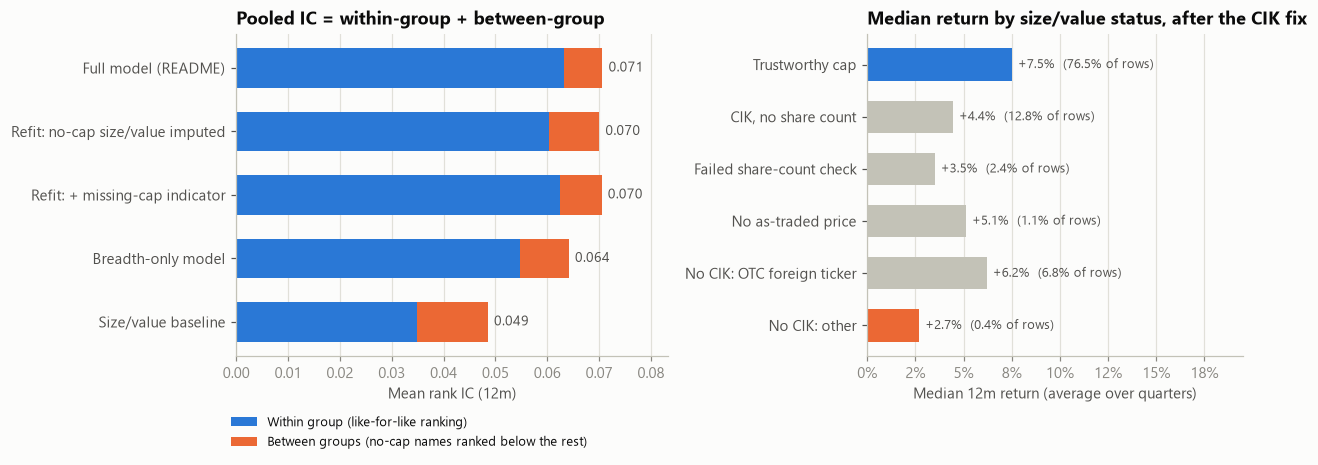

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
show = ["Full model (README)", "Full, refit: no-cap size/value imputed", "Full, refit: + missing-cap indicator",
        "Breadth-only model", "Size/value baseline"]
d = q10b.loc[show]
y = np.arange(len(show))[::-1]
ax1.barh(y, d["Within-group IC"], 0.62, color=BLUE, label="Within group (like-for-like ranking)")
ax1.barh(y, d["Between-group"], 0.62, left=d["Within-group IC"], color=ORANGE,
         label="Between groups (no-cap names ranked below the rest)")
for yy, tot in zip(y, d["Pooled IC"]):
    ax1.annotate(f"{tot:.3f}", (tot, yy), xytext=(4, 0), textcoords="offset points", va="center",
                 color=INK2, fontsize=9)
ax1.set_yticks(y, [s.replace("Full, refit: ", "Refit: ") for s in show])
ax1.tick_params(axis="y", colors=INK2)
ax1.grid(axis="y", visible=False)
ax1.grid(axis="x", visible=True)
ax1.set_xlim(0, d["Pooled IC"].max() * 1.18)
ax1.set_xlabel("Mean rank IC (12m)")
ax1.set_title("Pooled IC = within-group + between-group")
ax1.legend(loc="upper center", bbox_to_anchor=(0.4, -0.15), fontsize=8.5)

order = q10a.index[::-1]
yy = np.arange(len(order))
colors = [BLUE if g == GROUPS[0] else ORANGE if g == GROUPS[5] else AXIS for g in order]
med = q10a.loc[order, "Median 12m return"]
ax2.barh(yy, med, 0.62, color=colors)
for k, g in enumerate(order):
    ax2.annotate(f"{med[g]:+.1%}  ({q10a.loc[g, '% of rows']:.1%} of rows)", (max(med[g], 0), k),
                 xytext=(4, 0), textcoords="offset points", va="center", color=INK2, fontsize=8.5)
ax2.axvline(0, color=AXIS, lw=1)
ax2.set_yticks(yy, order)
ax2.tick_params(axis="y", colors=INK2)
ax2.grid(axis="y", visible=False)
ax2.grid(axis="x", visible=True)
ax2.xaxis.set_major_formatter(PCT)
ax2.set_xlim(min(med.min() * 1.15, 0), med.max() * 2.6)
ax2.set_xlabel("Median 12m return (average over quarters)")
ax2.set_title("Median return by size/value status, after the CIK fix")
fig.tight_layout()
plt.show()